In [1]:
# Install YOLOv5 dependencies
# pip install ultralytics opencv-python

from ultralytics import YOLO
import cv2

# 1. Load YOLO pretrained model
model = YOLO("yolo11m.pt")

# 2. Load your image
image_path = "sample_1.jpg"
img = cv2.imread(image_path)

# 3. Run object detection
results = model(image_path)  # Directly pass the file path

# 4. Display results
results[0].show()


image 1/1 C:\Users\Dale Menezes\Desktop\Computer-Vision\EXP-5\sample_1.jpg: 448x640 1 person, 1 bicycle, 1 bench, 1 bird, 1 dog, 605.4ms
Speed: 11.0ms preprocess, 605.4ms inference, 28.5ms postprocess per image at shape (1, 3, 448, 640)


In [6]:

#Automatically download pretrained weights
#Use only if you dont have it
import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(weights=weights)

torch.save(model, "fasterrcnn_offline.pth")

print("fasterrcnn_offline.pth created!")

fasterrcnn_offline.pth created!


In [7]:
# Faster R-CNN

import torch

# Load the entire model directly
model = torch.load("fasterrcnn_offline.pth", weights_only=False)

#weight_only=True → load only the numerical parameters/weights of the model.
#weight_only=False → allow loading the full saved object/checkpoint, which may include model architecture, configuration, optimizer state, etc.

#You are not training the model now. You are using it to make predictions.
model.eval();

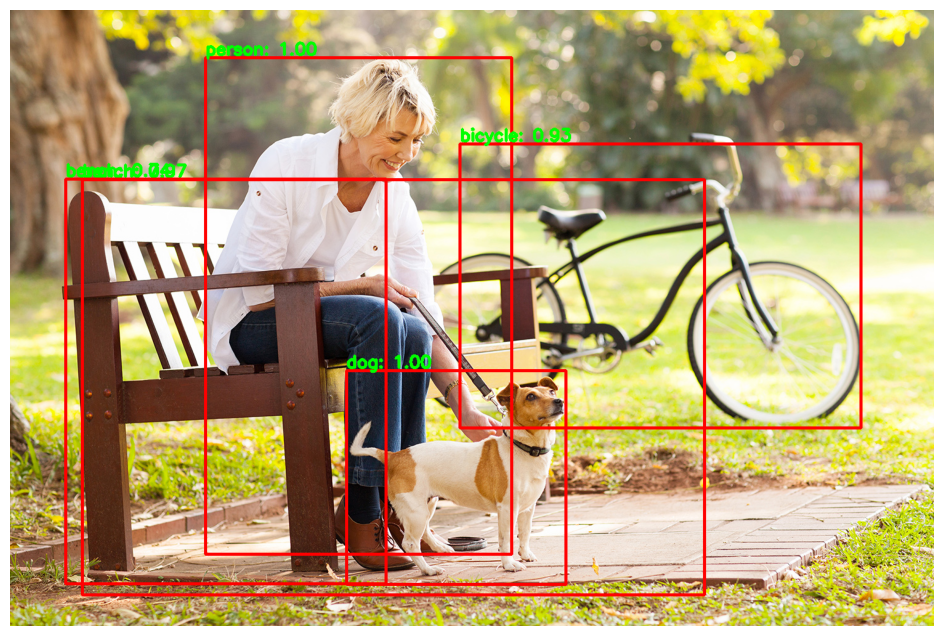

In [16]:
import cv2
from torchvision.transforms import functional as F 
#torchvision provides image-processing functions compatible with PyTorch.

import matplotlib.pyplot as plt

# 2. Load and preprocess image
image_path = "sample_1.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_tensor = F.to_tensor(image_rgb)  # This converts the OpenCV image from a NumPy array into a PyTorch tensor
#OpenCV/NumPy representation:(480, 640, 3)
#PyTorch vision models generally expect: (3, 480, 640)
#It also converts pixel values approximately from: 0 ─── 255 to 0.0 ─── 1.0

# 3. Run inference
with torch.no_grad():#Normally, PyTorch keeps track of operations so that it can calculate gradients during training.
                     #But here you're only using the trained model to make predictions.You don't need gradients.
    outputs = model([image_tensor]) #the model gives detection information.

# 4. Extract results
boxes = outputs[0]['boxes'] #boxes contains the coordinates of detected objects.For example:
                            #[[100, 50, 300, 400], [450, 100, 600, 350]]
                            #Each detection has:[x1, y1, x2, y2] The top-left corner is:(x1, y1) and bottom right is x2 and y2
labels = outputs[0]['labels']  #This contains the class ID predicted for each detected object.labels = [1, 3, 18] in coco.txt
scores = outputs[0]['scores'] #scores = [0.97, 0.84, 0.42]

# 5. Draw results on image
# extract labels from coco.txt
with open("coco.txt", "r") as f:
    COCO_INSTANCE_CATEGORY_NAMES = [line.strip() for line
                                  in f.readlines() if line.strip()] #line.strip() removes unnecessary whitespace and the newline character.
                                                                    #readlines() goes to the next line in coco.txt

for box, label, score in zip(boxes, labels, scores):      #Suppose: boxes  = [box1, box2, box3] labels = [person, dog, car]
                                                          #scores = [0.95, 0.88, 0.76]
                                                          #zip() pairs them: box1 → person → 0.95 | box2 → dog → 0.88
    if score >= 0.6:
        if label < len(COCO_INSTANCE_CATEGORY_NAMES): #"Is the label number within the range of the class-name list?"
            class_name = COCO_INSTANCE_CATEGORY_NAMES[label]
        else:
            class_name = f"Class_{label}"  # fallback name What if the label is invalid? instesad of crashing

        x1, y1, x2, y2 = box.int().tolist()
        #The model gives the coordinates as a PyTorch tensor. tensor([100.5, 50.3, 300.8, 400.2])
        #box.int() converts them to integers: 100, 50, 300, 400
        cv2.rectangle(image_rgb, (x1, y1), (x2, y2), (255, 0, 0), 4) #red color of thickness 4
        cv2.putText(image_rgb, f"{class_name}: {score:.2f}",
                (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.9,  #(x1,y1-5) This tells OpenCV where to put the text. moves the text 5 pixels upward.
                 (0, 255, 0), 4)

# 6. Show result
plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

In [14]:
print(COCO_INSTANCE_CATEGORY_NAMES[15])

bench
